# Human Activity Recognition from Wearable Sensors (HAR70+)

Classify what a person is doing (walking, sitting, lying, stairs and so on) from two accelerometers, one on the lower back and one on the thigh.

- Dataset: [HAR70+ (UCI)](https://archive.ics.uci.edu/dataset/780/har70), CC BY 4.0, 18 older adults, 50 Hz, 2,259,597 rows
- Put the 18 subject files (`501.csv` to `518.csv`) in a `data/` folder next to this notebook
- Method: 2-second windows with 50% overlap, summary features per axis, Random Forest
- Evaluation: whole subjects are held out, so the model is always tested on people it has never seen

In [1]:
import glob
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Settings used across the notebook
sensor_cols = ['back_x', 'back_y', 'back_z', 'thigh_x', 'thigh_y', 'thigh_z']
label_map = {1: 'Walking', 3: 'Shuffling', 4: 'Stairs Up', 5: 'Stairs Down',
             6: 'Standing', 7: 'Sitting', 8: 'Lying'}

DATA_DIR = "data" if os.path.isdir("data") else "."

# Load only the subject files (501.csv ... 518.csv), always in the same order
subject_files = sorted(f for f in glob.glob(os.path.join(DATA_DIR, "*.csv"))
                       if re.fullmatch(r"\d{3}\.csv", os.path.basename(f)))
if not subject_files:
    raise FileNotFoundError("No subject files (501.csv ... 518.csv) found. "
                            "Put them in a 'data' folder next to this notebook.")

df_list = []
for file in subject_files:
    subject_df = pd.read_csv(file).sort_values('timestamp', kind='stable')
    # File name (e.g. '501') identifies the subject
    subject_df['subject_id'] = os.path.basename(file).split('.')[0]
    df_list.append(subject_df)

# Combine everything into one master dataset
full_df = pd.concat(df_list, ignore_index=True)

print(f"All data loaded successfully: {len(subject_files)} subjects, {len(full_df):,} rows")

All data loaded successfully: 18 subjects, 2,259,597 rows


In [2]:
print("First 5 rows")
display(full_df.head())

First 5 rows


,timestamp,back_x,back_y,back_z,thigh_x,thigh_y,thigh_z,label,subject_id
0,2021-03-24 14:42:03.839,-0.999023,-0.063477,0.140625,-0.980469,-0.112061,-0.048096,6,501
1,2021-03-24 14:42:03.859,-0.980225,-0.079346,0.140625,-0.961182,-0.121582,-0.051758,6,501
2,2021-03-24 14:42:03.880,-0.950195,-0.076416,0.140625,-0.949463,-0.080566,-0.067139,6,501
3,2021-03-24 14:42:03.900,-0.954834,-0.059082,0.140381,-0.957520,-0.046143,-0.050781,6,501
4,2021-03-24 14:42:03.920,-0.972412,-0.042969,0.142822,-0.977051,-0.023682,-0.026611,6,501


In [3]:
print("Dataset blueprint")
full_df.info()
print("Column names")
print(full_df.columns.tolist())

Dataset blueprint
<class 'pandas.DataFrame'>
RangeIndex: 2259597 entries, 0 to 2259596
Data columns (total 9 columns):
 #   Column      Dtype  
---  ------      -----  
 0   timestamp   str    
 1   back_x      float64
 2   back_y      float64
 3   back_z      float64
 4   thigh_x     float64
 5   thigh_y     float64
 6   thigh_z     float64
 7   label       int64  
 8   subject_id  str    
dtypes: float64(6), int64(1), str(2)
memory usage: 155.2 MB
Column names
['timestamp', 'back_x', 'back_y', 'back_z', 'thigh_x', 'thigh_y', 'thigh_z', 'label', 'subject_id']


In [4]:
# dataset size 
print(f"Total Rows: {full_df.shape[0]}")
print(f"Total Columns: {full_df.shape[1]}")
print(f"Total Subjects: {full_df['subject_id'].nunique()}")

#missing values
# If this outputs numbers higher than 0, you have missing data to clean
print(full_df.isnull().sum())

print("Class imbalance activity percentages")
# This shows if the dataset is mostly sitting/walking/etc.
print(full_df['label'].value_counts(normalize=True) * 100)

Total Rows: 2259597
Total Columns: 9
Total Subjects: 18


timestamp     0
back_x        0
back_y        0
back_z        0
thigh_x       0
thigh_y       0
thigh_z       0
label         0
subject_id    0
dtype: int64
Class imbalance activity percentages
label
1    47.765686
7    21.395497
6    18.501308
8     8.991957
3     2.923442
5     0.220305
4     0.201806
Name: proportion, dtype: float64


In [5]:
print("Data per subject:")
print(full_df['subject_id'].value_counts())

Data per subject:


subject_id
515    153517
504    150758
517    147045
518    141714
516    138278
502    131367
508    130494
511    128063
513    123599
506    122714
510    122061
509    121763
507    120125
512    119310
503    116413
501    103860
514    101510
505     87006
Name: count, dtype: int64


In [6]:
# checking for missing data (on the full dataset, all subjects)
missing_data = full_df.isnull().sum()
print(missing_data)
if missing_data.sum() == 0:
    print("Result: The dataset is perfectly clean. No imputation required.")
else:
    print("Result: Missing values detected. We will need to interpolate or drop these rows.")
# checking for duplicate rows
duplicates = full_df.duplicated().sum()
print(f"Duplicate rows found: {duplicates}")

timestamp     0
back_x        0
back_y        0
back_z        0
thigh_x       0
thigh_y       0
thigh_z       0
label         0
subject_id    0
dtype: int64
Result: The dataset is perfectly clean. No imputation required.


Duplicate rows found: 0


In [7]:
full_df['activity'] = full_df['label'].map(label_map)
# mean sensor values per activity
display(full_df.groupby('activity')[sensor_cols].mean().round(3))
# standard deviation
display(full_df.groupby('activity')[sensor_cols].std().round(3))

,back_x,back_y,back_z,thigh_x,thigh_y,thigh_z
activity,,,,,,
Lying,-0.193,-0.057,0.876,0.049,0.081,-0.951
Shuffling,-0.971,-0.024,-0.197,-0.969,-0.014,-0.114
Sitting,-0.835,-0.024,0.390,0.010,0.056,-1.025
Stairs Down,-0.964,-0.030,-0.235,-0.925,0.006,-0.347
Stairs Up,-0.926,-0.030,-0.324,-0.879,0.026,-0.403
Standing,-0.972,-0.033,-0.147,-0.968,-0.019,-0.034
Walking,-0.967,-0.034,-0.219,-0.994,-0.026,-0.143


,back_x,back_y,back_z,thigh_x,thigh_y,thigh_z
activity,,,,,,
Lying,0.175,0.284,0.129,0.089,0.346,0.297
Shuffling,0.056,0.116,0.185,0.099,0.184,0.196
Sitting,0.152,0.115,0.308,0.127,0.172,0.063
Stairs Down,0.197,0.162,0.174,0.299,0.267,0.327
Stairs Up,0.157,0.131,0.185,0.285,0.219,0.323
Standing,0.042,0.088,0.218,0.030,0.108,0.155
Walking,0.182,0.151,0.234,0.420,0.332,0.406


In [8]:
# Transpose (.T) makes it easier to read horizontally
display(full_df[sensor_cols].describe().T)
# Check the variance to see which axes capture the most dynamic movement
print("Sensor variance")
display(full_df[sensor_cols].var().sort_values(ascending=False))

,count,mean,std,min,25%,50%,75%,max
back_x,2259597.0,-0.869934,0.268912,-4.333252,-0.992920,-0.939209,-0.828125,0.363037
back_y,2259597.0,-0.033168,0.151327,-2.031006,-0.109619,-0.021729,0.050781,1.576660
back_z,2259597.0,0.023425,0.432736,-2.204834,-0.275146,-0.112549,0.312500,1.179199
thigh_x,2259597.0,-0.679621,0.551754,-7.942139,-0.987305,-0.935791,-0.070557,3.395264
thigh_y,2259597.0,0.002775,0.273696,-5.142578,-0.116699,-0.015625,0.112305,5.725098
thigh_z,2259597.0,-0.384122,0.512776,-7.593750,-0.986084,-0.187744,-0.004150,3.953369


Sensor variance


thigh_x    0.304432
thigh_z    0.262939
back_z     0.187260
thigh_y    0.074909
back_x     0.072314
back_y     0.022900
dtype: float64

In [9]:
# Values outside -1 to 1 indicate highly skewed data
display(full_df[sensor_cols].skew().round(2))
# High values indicate heavy tails (a lot of extreme physical spikes/outliers)
display(full_df[sensor_cols].kurtosis().round(2))

back_x     1.32
back_y    -1.15
back_z     0.71
thigh_x   -0.24
thigh_y    0.50
thigh_z   -0.40
dtype: float64

back_x      3.39
back_y      6.80
back_z     -0.43
thigh_x     2.46
thigh_y    17.38
thigh_z     0.11
dtype: float64

In [10]:
import numpy as np
# calc total acc vector for thigh sensor
full_df['thigh_magnitude'] = np.sqrt(
    full_df['thigh_x']**2 + full_df['thigh_y']**2 + full_df['thigh_z']**2
)
display(full_df.groupby('activity')['thigh_magnitude'].mean().round(3))

activity
Lying          1.062
Shuffling      1.010
Sitting        1.049
Stairs Down    1.068
Stairs Up      1.049
Standing       0.987
Walking        1.120
Name: thigh_magnitude, dtype: float64

In [11]:
# Calculate the exact percentages of each activity in the full dataset
class_distribution = full_df['activity'].value_counts(normalize=True) * 100
print("Class Imbalance")
print(class_distribution.round(2).astype(str) + '%')

Class Imbalance
activity
Walking        47.77%
Sitting         21.4%
Standing        18.5%
Lying           8.99%
Shuffling       2.92%
Stairs Down     0.22%
Stairs Up        0.2%
Name: proportion, dtype: str


In [12]:
subject_contribution = full_df['subject_id'].value_counts(normalize=True) * 100
print("Data contribution per subject")
print(subject_contribution.round(2).astype(str) + '%')

Data contribution per subject
subject_id
515    6.79%
504    6.67%
517    6.51%
518    6.27%
516    6.12%
502    5.81%
508    5.78%
511    5.67%
513    5.47%
506    5.43%
510     5.4%
509    5.39%
507    5.32%
512    5.28%
503    5.15%
501     4.6%
514    4.49%
505    3.85%
Name: proportion, dtype: str


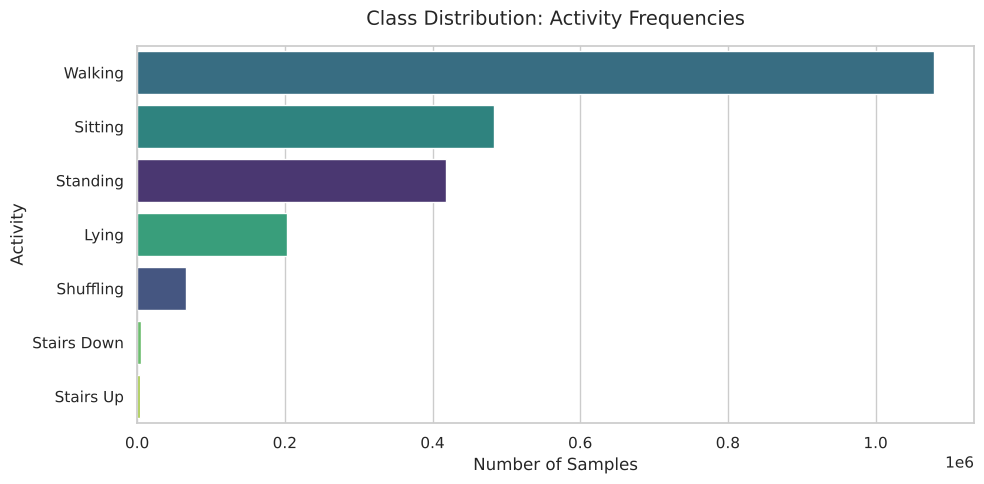

In [13]:
# data visualisation
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="muted")
label_map = {1: 'Walking', 3: 'Shuffling', 4: 'Stairs Up', 5: 'Stairs Down', 
             6: 'Standing', 7: 'Sitting', 8: 'Lying'}
if 'activity' not in full_df.columns:
    full_df['activity'] = full_df['label'].map(label_map)
plt.figure(figsize=(10, 5))
order = full_df['activity'].value_counts().index
sns.countplot(data=full_df, y='activity', hue='activity', order=order, palette='viridis', legend=False)
plt.title("Class Distribution: Activity Frequencies", fontsize=14, pad=15)
plt.xlabel("Number of Samples", fontsize=12)
plt.ylabel("Activity", fontsize=12)
plt.tight_layout()
plt.show()

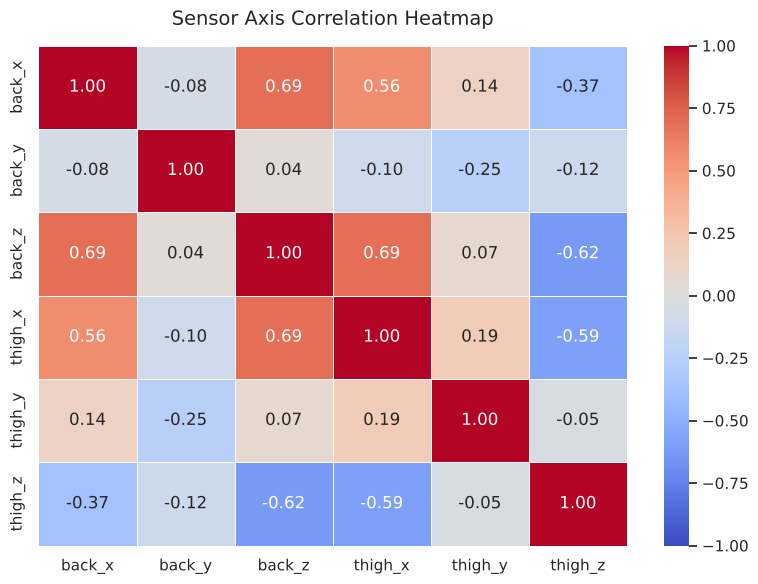

In [14]:
# Correlation Heatmap
sensor_cols = ['back_x', 'back_y', 'back_z', 'thigh_x', 'thigh_y', 'thigh_z']
plt.figure(figsize=(8, 6))
corr_matrix = full_df[sensor_cols].corr()
# Draw the heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", 
            linewidths=0.5, vmin=-1, vmax=1)
plt.title("Sensor Axis Correlation Heatmap", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

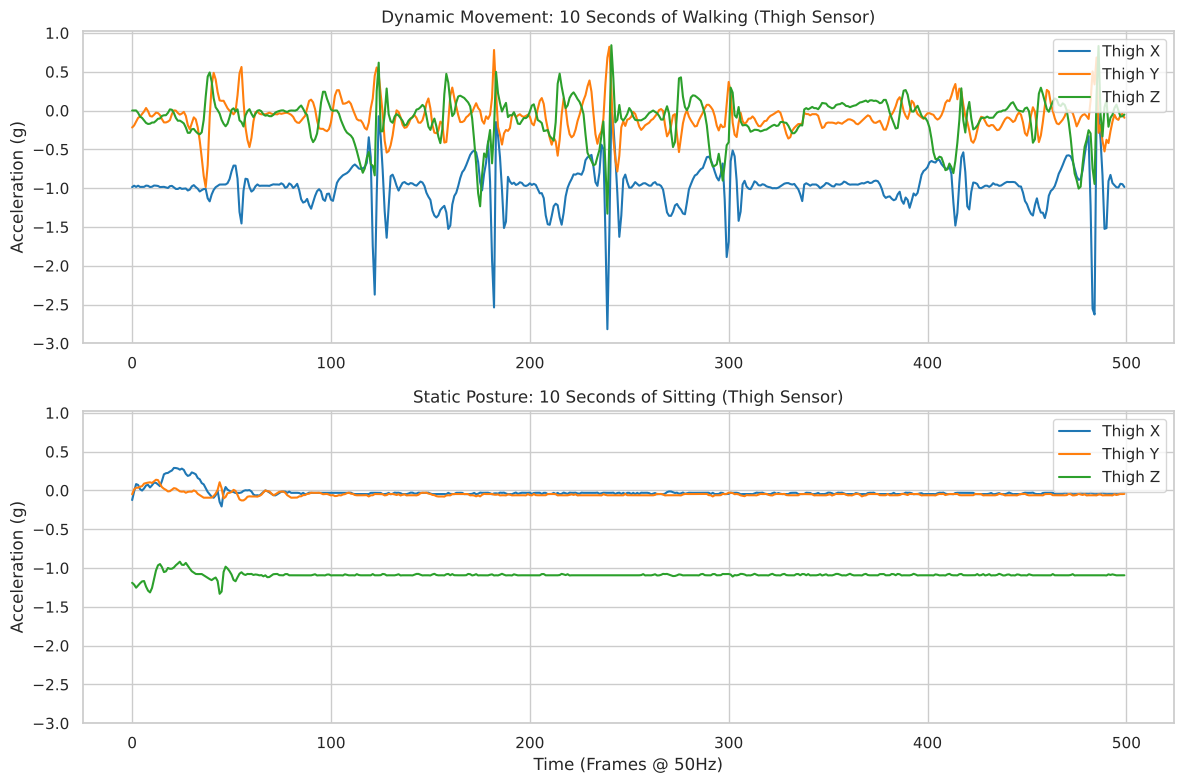

In [15]:
# Waveform Visualization (Dynamic vs. Static)
# Grab exactly 10 seconds (500 frames at 50Hz) of data
walking_sample = full_df[full_df['activity'] == 'Walking'].head(500).reset_index()
sitting_sample = full_df[full_df['activity'] == 'Sitting'].head(500).reset_index()
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharey=True)
# Top Plot: Walking (the rhythmic bouncing)
axes[0].plot(walking_sample.index, walking_sample['thigh_x'], label='Thigh X', color='#1f77b4')
axes[0].plot(walking_sample.index, walking_sample['thigh_y'], label='Thigh Y', color='#ff7f0e')
axes[0].plot(walking_sample.index, walking_sample['thigh_z'], label='Thigh Z', color='#2ca02c')
axes[0].set_title("Dynamic Movement: 10 Seconds of Walking (Thigh Sensor)", fontsize=12)
axes[0].legend(loc="upper right")
axes[0].set_ylabel("Acceleration (g)")
# Bottom Plot: Sitting (flat lines representing gravity)
axes[1].plot(sitting_sample.index, sitting_sample['thigh_x'], label='Thigh X', color='#1f77b4')
axes[1].plot(sitting_sample.index, sitting_sample['thigh_y'], label='Thigh Y', color='#ff7f0e')
axes[1].plot(sitting_sample.index, sitting_sample['thigh_z'], label='Thigh Z', color='#2ca02c')
axes[1].set_title("Static Posture: 10 Seconds of Sitting (Thigh Sensor)", fontsize=12)
axes[1].legend(loc="upper right")
axes[1].set_xlabel("Time (Frames @ 50Hz)", fontsize=12)
axes[1].set_ylabel("Acceleration (g)")
plt.tight_layout()
plt.show()

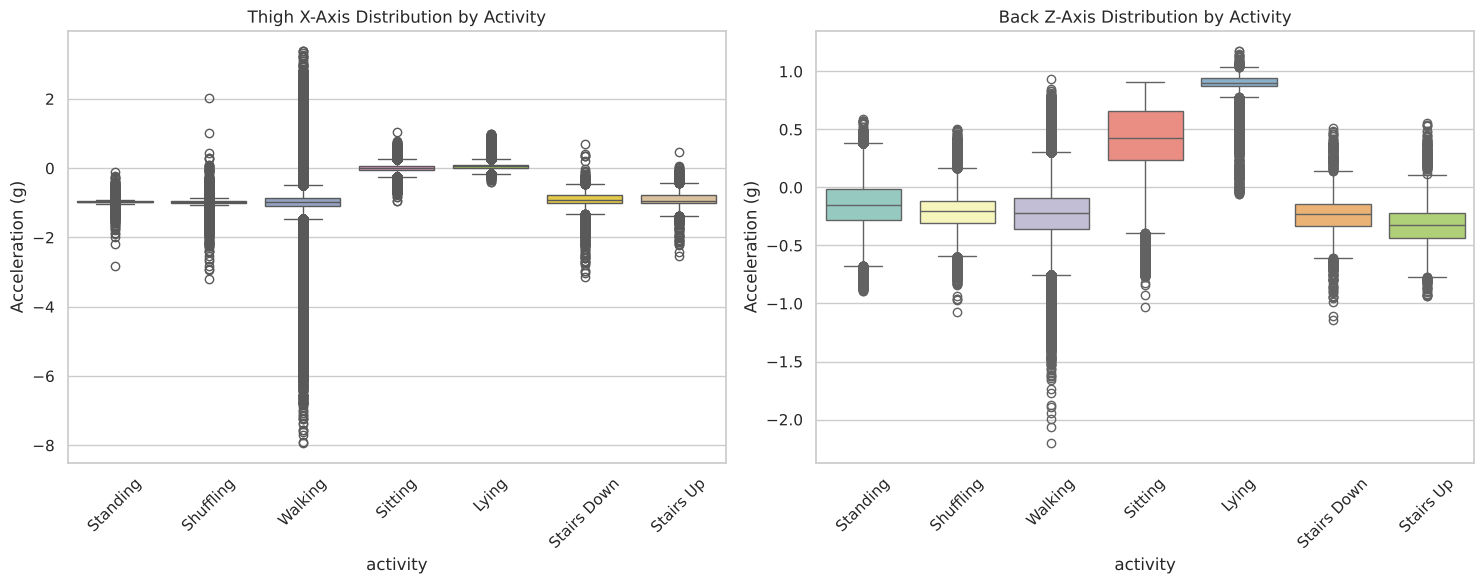

In [16]:
#box plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.boxplot(ax=axes[0], data=full_df, x='activity', y='thigh_x', hue='activity', palette='Set2', legend=False)
axes[0].set_title("Thigh X-Axis Distribution by Activity", fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylabel("Acceleration (g)")

sns.boxplot(ax=axes[1], data=full_df, x='activity', y='back_z', hue='activity', palette='Set3', legend=False)
axes[1].set_title("Back Z-Axis Distribution by Activity", fontsize=12)
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylabel("Acceleration (g)")

plt.tight_layout()
plt.show()

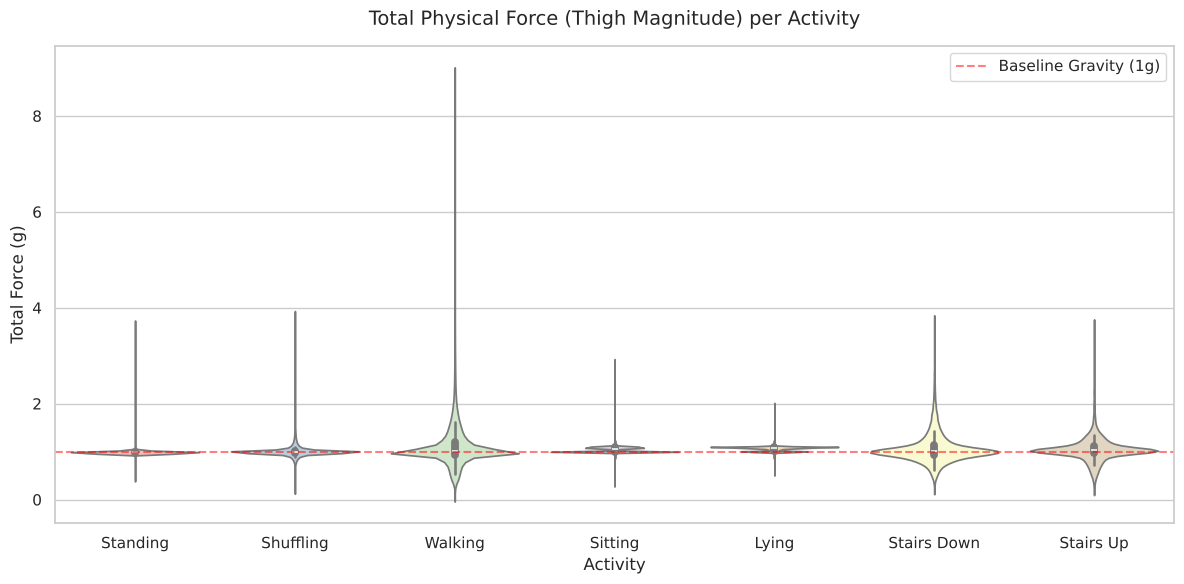

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate total acceleration vector: sqrt(x^2 + y^2 + z^2)
full_df['thigh_magnitude'] = np.sqrt(
    full_df['thigh_x']**2 + full_df['thigh_y']**2 + full_df['thigh_z']**2
)

plt.figure(figsize=(12, 6))
sns.violinplot(data=full_df, x='activity', y='thigh_magnitude', 
               hue='activity', palette='Pastel1', legend=False)

plt.title("Total Physical Force (Thigh Magnitude) per Activity", fontsize=14, pad=15)
plt.xlabel("Activity", fontsize=12)
plt.ylabel("Total Force (g)", fontsize=12)

# Draw a dashed line at 1.0 (baseline gravity)
plt.axhline(1.0, color='red', linestyle='--', alpha=0.5, label='Baseline Gravity (1g)')
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
# data pre-processing: sliding windows -> summary features
sampling_rate = 50                                   # 50 Hz
window_seconds = 2
overlap = 0.5
window_size = int(sampling_rate * window_seconds)    # 100 samples per window
step_size = int(window_size * (1 - overlap))         # slide forward by 50 samples


def extract_features(subject_data):
    """Cut one subject's signal into 2-second windows and compute mean/std/max/min per axis."""
    values = subject_data[sensor_cols].to_numpy()
    labels = subject_data['label'].to_numpy()
    if len(values) < window_size:
        return pd.DataFrame()

    n_windows = (len(values) - window_size) // step_size + 1
    idx = (np.arange(n_windows) * step_size)[:, None] + np.arange(window_size)[None, :]
    win = values[idx]                                # (n_windows, window_size, n_axes)

    feats = {}
    for j, col in enumerate(sensor_cols):
        feats[f'{col}_mean'] = win[:, :, j].mean(axis=1)
        feats[f'{col}_std'] = win[:, :, j].std(axis=1, ddof=1)
        feats[f'{col}_max'] = win[:, :, j].max(axis=1)
        feats[f'{col}_min'] = win[:, :, j].min(axis=1)

    # Label of a window = most common activity inside the window
    feats['label'] = np.array([np.bincount(w).argmax() for w in labels[idx]])
    return pd.DataFrame(feats)


print("Starting Feature Extraction...")
features_list = []

# Each subject is processed on its own, so no window mixes two different people
for subject in sorted(full_df['subject_id'].unique()):
    subject_data = full_df[full_df['subject_id'] == subject].reset_index(drop=True)
    subject_features = extract_features(subject_data)
    subject_features['subject_id'] = subject
    features_list.append(subject_features)
    print(f"Subject {subject}: {len(subject_features)} windows")

# Convert the extracted features into a brand new DataFrame
ml_df = pd.concat(features_list, ignore_index=True)

print("Feature Extraction Completed")
print(f"Original Raw Rows: {len(full_df)}")
print(f"New ML-Ready Rows (Windows): {len(ml_df)}")

Starting Feature Extraction...


Subject 501: 2076 windows


Subject 502: 2626 windows


Subject 503: 2327 windows


Subject 504: 3014 windows


...

Subject 514: 2029 windows


Subject 515: 3069 windows


Subject 516: 2764 windows


Subject 517: 2939 windows


Subject 518: 2833 windows
Feature Extraction Completed
Original Raw Rows: 2259597
New ML-Ready Rows (Windows): 45167


In [19]:
# new ml dataset
display(ml_df.head())
# total number of features created
print(f"\nTotal Features for the ML Model: {len(ml_df.columns) - 2}") # Subtracting 'label' and 'subject_id'

,back_x_mean,back_x_std,back_x_max,back_x_min,back_y_mean,back_y_std,back_y_max,back_y_min,back_z_mean,back_z_std,...,thigh_y_mean,thigh_y_std,thigh_y_max,thigh_y_min,thigh_z_mean,thigh_z_std,thigh_z_max,thigh_z_min,label,subject_id
0,-0.946553,0.022176,-0.906250,-1.001953,-0.045574,0.011708,-0.016113,-0.083252,0.263274,0.053883,...,-0.050930,0.015559,-0.023682,-0.121582,0.029995,0.046102,0.113037,-0.067139,6,501
1,-0.924236,0.009397,-0.902588,-0.954834,-0.043957,0.006059,-0.028564,-0.049072,0.318311,0.020519,...,-0.030715,0.013364,-0.013184,-0.058838,0.083511,0.023906,0.113037,0.020264,6,501
2,-0.918174,0.006654,-0.902588,-0.924072,-0.046719,0.003419,-0.031006,-0.062256,0.331306,0.013033,...,-0.020845,0.007399,-0.013184,-0.032715,0.094631,0.009090,0.111572,0.075684,6,501
3,-0.914499,0.007711,-0.902344,-0.925537,-0.043123,0.007116,-0.027344,-0.062256,0.336182,0.014722,...,-0.022297,0.007570,-0.011719,-0.033447,0.093967,0.010430,0.111572,0.075684,6,501
4,-0.917263,0.007054,-0.902344,-0.925537,-0.042991,0.006523,-0.027344,-0.049072,0.333577,0.010545,...,-0.016697,0.009357,0.003662,-0.033447,0.097468,0.009059,0.112305,0.075928,6,501



Total Features for the ML Model: 24


In [20]:
# training and splitting the data
from sklearn.preprocessing import StandardScaler
print("Subject-wise train/test split")

# Hold out 4 whole subjects. The model never sees these people during training.
# One subject alone can have only a couple of Stairs windows, which makes the
# per-class scores meaningless, so several subjects are held out together.
# Stairs are very rare, so the cross-validated results further below are the more reliable ones.
all_subjects = sorted(ml_df['subject_id'].unique())
rng = np.random.RandomState(42)
test_subjects = sorted(str(s) for s in rng.choice(all_subjects, size=4, replace=False))
train_subjects = [s for s in all_subjects if s not in test_subjects]
print(f"Training on Subjects: {train_subjects}")
print(f"Testing on Subjects: {test_subjects}")

# Split the DataFrame based on the subjects
train_df = ml_df[ml_df['subject_id'].isin(train_subjects)]
test_df = ml_df[ml_df['subject_id'].isin(test_subjects)]

# 'label' is the target and 'subject_id' is not a physical feature, so both are dropped from X
X_train = train_df.drop(columns=['label', 'subject_id'])
y_train = train_df['label']
X_test = test_df.drop(columns=['label', 'subject_id'])
y_test = test_df['label']

# Standardise: mean 0 and std 1, fitted on training data only
# (not needed for a Random Forest, kept so other models can be swapped in)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining Data Shape: {X_train_scaled.shape} (Rows, Features)")
print(f"Testing Data Shape: {X_test_scaled.shape} (Rows, Features)")
print("\nWindows per activity in the test subjects:")
print(y_test.map(label_map).value_counts())

Subject-wise train/test split


Training on Subjects: ['503', '504', '505', '507', '508', '510', '511', '512', '513', '514', '515', '516', '517', '518']
Testing on Subjects: ['501', '502', '506', '509']

Training Data Shape: (35578, 24) (Rows, Features)
Testing Data Shape: (9589, 24) (Rows, Features)

Windows per activity in the test subjects:
label
Walking        5144
Sitting        1804
Standing       1453
Lying           891
Shuffling       248
Stairs Down      28
Stairs Up        21
Name: count, dtype: int64


In [21]:
# Model training
from sklearn.ensemble import RandomForestClassifier
import time
print("Training Random Forest Model")
# Initialize the model
# n_estimators=100 means we are building a forest of 100 decision trees
# class_weight='balanced' helps fix the fact that we have way more 'Sitting' than 'Walking'
rf_model = RandomForestClassifier(n_estimators=100, 
                                  class_weight='balanced', 
                                  random_state=42, 
                                  n_jobs=-1) # n_jobs=-1 uses all CPU cores to train faster
# Train the model and time it
start_time = time.time()
rf_model.fit(X_train_scaled, y_train)
end_time = time.time()
print(f"Model training complete in {round(end_time - start_time, 2)} seconds!")

Training Random Forest Model


Model training complete in 10.35 seconds!


In [22]:
# testing our model
from sklearn.metrics import accuracy_score, f1_score, classification_report
print("Model Evaluation")

# Make predictions on the unseen test subjects
y_pred = rf_model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
print(f"Overall Accuracy: {accuracy * 100:.2f}%")
print(f"Macro F1 (every activity counts equally): {macro_f1:.3f}\n")

# Accuracy is dominated by Walking/Sitting, so the per-activity report matters more
present_labels = sorted(set(y_test) | set(y_pred))
target_names = [label_map[label] for label in present_labels]
print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, labels=present_labels,
                            target_names=target_names, zero_division=0))

Model Evaluation
Overall Accuracy: 89.79%
Macro F1 (every activity counts equally): 0.567

Detailed Classification Report:
              precision    recall  f1-score   support

     Walking       0.97      0.97      0.97      5144
   Shuffling       0.45      0.36      0.40       248
   Stairs Up       0.50      0.05      0.09        21
 Stairs Down       0.00      0.00      0.00        28
    Standing       0.88      0.96      0.92      1453
     Sitting       1.00      0.70      0.82      1804
       Lying       0.62      1.00      0.77       891

    accuracy                           0.90      9589
   macro avg       0.63      0.58      0.57      9589
weighted avg       0.91      0.90      0.90      9589



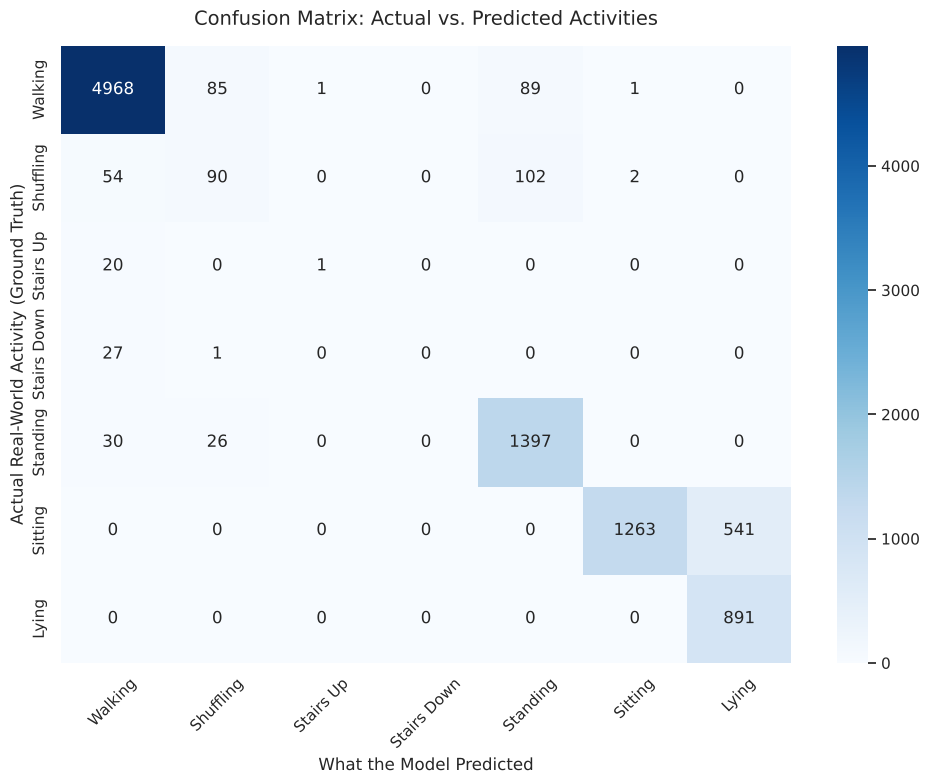

In [23]:
# Confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=present_labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names)
plt.title("Confusion Matrix: Actual vs. Predicted Activities", fontsize=14, pad=15)
plt.ylabel("Actual Real-World Activity (Ground Truth)", fontsize=12)
plt.xlabel("What the Model Predicted", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Cross-validated accuracy: 91.21%
Cross-validated macro F1: 0.629

              precision    recall  f1-score   support

     Walking       0.96      0.92      0.94     21731
   Shuffling       0.28      0.30      0.29      1157
   Stairs Up       0.33      0.07      0.12        94
 Stairs Down       0.89      0.17      0.29        99
    Standing       0.84      0.94      0.89      8353
     Sitting       0.99      0.93      0.96      9668
       Lying       0.87      0.98      0.92      4065

    accuracy                           0.91     45167
   macro avg       0.74      0.62      0.63     45167
weighted avg       0.92      0.91      0.91     45167



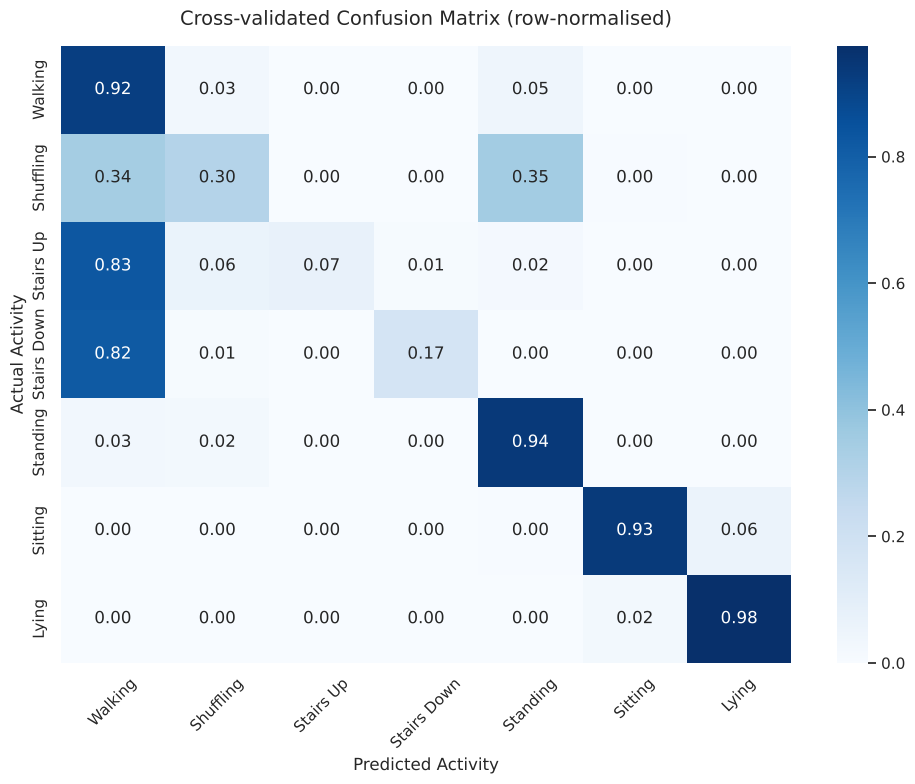

In [24]:
# Cross-validation across subjects
# Every window gets predicted by a model that never saw that person. This uses all 18
# subjects, so even rare activities (stairs) have enough windows to judge.
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier

X_all = ml_df.drop(columns=['label', 'subject_id'])
y_all = ml_df['label']
groups_all = ml_df['subject_id']

cv_model = RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                  random_state=42, n_jobs=-1)
y_cv_pred = cross_val_predict(cv_model, X_all, y_all, cv=GroupKFold(n_splits=6), groups=groups_all)

cv_labels = sorted(set(y_all) | set(y_cv_pred))
cv_names = [label_map[l] for l in cv_labels]
print(f"Cross-validated accuracy: {accuracy_score(y_all, y_cv_pred) * 100:.2f}%")
print(f"Cross-validated macro F1: {f1_score(y_all, y_cv_pred, average='macro', zero_division=0):.3f}\n")
print(classification_report(y_all, y_cv_pred, labels=cv_labels, target_names=cv_names, zero_division=0))

# Row-normalised confusion matrix: each row shows what share of an activity was predicted as what
cm_cv = confusion_matrix(y_all, y_cv_pred, labels=cv_labels, normalize='true')
plt.figure(figsize=(10, 8))
sns.heatmap(cm_cv, annot=True, fmt='.2f', cmap='Blues', xticklabels=cv_names, yticklabels=cv_names)
plt.title("Cross-validated Confusion Matrix (row-normalised)", fontsize=14, pad=15)
plt.ylabel("Actual Activity", fontsize=12)
plt.xlabel("Predicted Activity", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
# model tuning
from sklearn.model_selection import RandomizedSearchCV
print("Hyperparameter tuning")

# Settings to try
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

base_rf = RandomForestClassifier(class_weight='balanced', random_state=42)

# Two changes compared with a plain search:
# 1. GroupKFold with subject groups: neighbouring windows overlap by 50%, so a normal
#    random fold would show the model near-copies of its validation windows.
# 2. scoring='f1_macro': plain accuracy is dominated by Walking and Sitting.
random_search = RandomizedSearchCV(estimator=base_rf,
                                   param_distributions=param_grid,
                                   n_iter=10,
                                   cv=GroupKFold(n_splits=3),
                                   scoring='f1_macro',
                                   verbose=1,
                                   random_state=42,
                                   n_jobs=-1)

# This can take several minutes depending on the CPU
start_time = time.time()
random_search.fit(X_train_scaled, y_train, groups=train_df['subject_id'])
end_time = time.time()

print(f"Tuning complete in {round((end_time - start_time) / 60, 2)} minutes!")

Hyperparameter tuning
Fitting 3 folds for each of 10 candidates, totalling 30 fits


Tuning complete in 2.4 minutes!


In [26]:
# extracting and evaluating the best model
print("Tuning results")
print("Best Parameters Found:")
print(random_search.best_params_)

best_rf_model = random_search.best_estimator_
y_pred_optimized = best_rf_model.predict(X_test_scaled)

print(f"\nBaseline  accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%  | macro F1: {f1_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print(f"Optimized accuracy: {accuracy_score(y_test, y_pred_optimized) * 100:.2f}%  | macro F1: {f1_score(y_test, y_pred_optimized, average='macro', zero_division=0):.3f}\n")

present_opt = sorted(set(y_test) | set(y_pred_optimized))
print("Optimized Classification Report:")
print(classification_report(y_test, y_pred_optimized, labels=present_opt,
                            target_names=[label_map[l] for l in present_opt], zero_division=0))

Tuning results
Best Parameters Found:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 30}

Baseline  accuracy: 89.79%  | macro F1: 0.567


Optimized accuracy: 89.55%  | macro F1: 0.592

Optimized Classification Report:


              precision    recall  f1-score   support

     Walking       0.98      0.96      0.97      5144
   Shuffling       0.40      0.52      0.45       248
   Stairs Up       0.43      0.14      0.21        21
 Stairs Down       0.00      0.00      0.00        28
    Standing       0.90      0.95      0.92      1453
     Sitting       1.00      0.70      0.82      1804
       Lying       0.62      1.00      0.77       891

    accuracy                           0.90      9589
   macro avg       0.62      0.61      0.59      9589
weighted avg       0.92      0.90      0.90      9589

